Model Siap! (Train: 15600 | Test: 2000)
Akurasi RF: 99.60% | Akurasi SVM: 93.00%


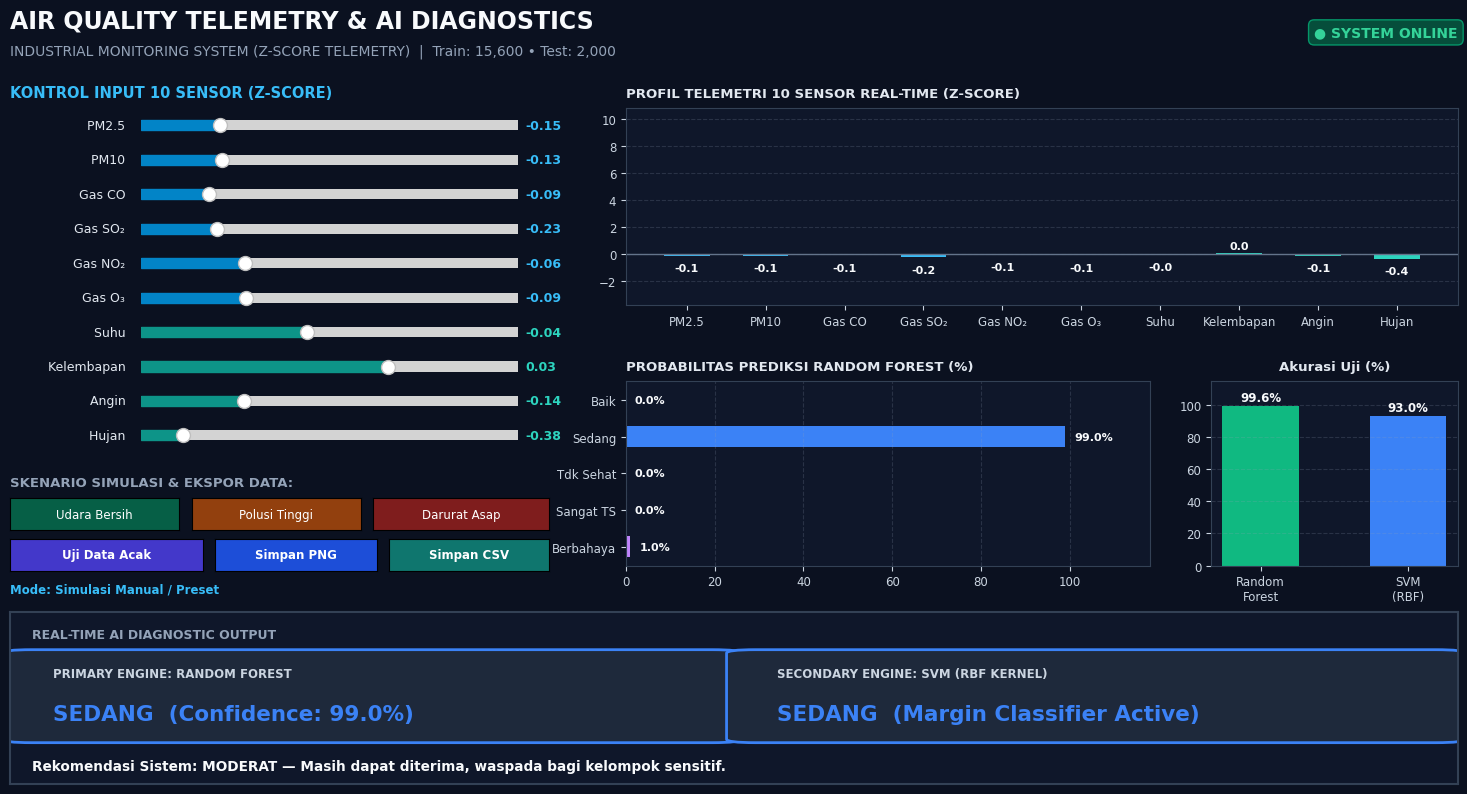

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider, Button
from matplotlib.patches import FancyBboxPatch
from datetime import datetime

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# ==========================================
# 1. LOAD DATASET TRAIN & TEST (SEPARATOR ';')
# ==========================================
train_df = pd.read_csv('Train_Data1_20pct.csv', sep=';')
test_df = pd.read_csv('Test_Data1_20pct.csv', sep=';')

fitur_sensor = [
    'pm25_concentration_ugm3',
    'pm10_concentration_ugm3',
    'carbon_monoxide_co_ugm3',
    'sulfur_dioxide_so2_ugm3',
    'nitrogen_dioxide_no2_ugm3',
    'ozone_o3_ugm3',
    'ambient_temperature_celsius',
    'relative_humidity_pct',
    'wind_speed_kmh',
    'rainfall_intensity_mm'
]

train_clean = train_df[fitur_sensor + ['Target_Encoded']].dropna()
test_clean = test_df[fitur_sensor + ['Target_Encoded']].dropna().reset_index(drop=True)

X_train = train_clean[fitur_sensor]
y_train = train_clean['Target_Encoded'].astype(int)

X_test = test_clean[fitur_sensor]
y_test = test_clean['Target_Encoded'].astype(int)

label_kategori = {
    0: 'Baik',
    1: 'Berbahaya',
    2: 'Sangat Tidak Sehat',
    3: 'Sedang',
    4: 'Tidak Sehat'
}

# ==========================================
# 2. PELATIHAN MODEL (RF & SVM)
# ==========================================
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

svm_model = SVC(kernel='rbf', C=1.0, random_state=42)
svm_model.fit(X_train, y_train)

acc_rf = accuracy_score(y_test, rf_model.predict(X_test)) * 100
acc_svm = accuracy_score(y_test, svm_model.predict(X_test)) * 100
print(f"Model Siap! (Train: {len(X_train)} | Test: {len(X_test)})")
print(f"Akurasi RF: {acc_rf:.2f}% | Akurasi SVM: {acc_svm:.2f}%")

# ==========================================
# 3. DASHBOARD INTERAKTIF & GRAFIK TELEMETRI
# ==========================================
plt.rcParams['toolbar'] = 'None'
fig = plt.figure(figsize=(15.4, 8.4), facecolor='#0b1120')
fig.canvas.manager.set_window_title('Industrial Air Quality Telemetry & AI Diagnostics')

# Header Dashboard
fig.text(0.03, 0.94, 'AIR QUALITY TELEMETRY & AI DIAGNOSTICS', fontsize=17, fontweight='bold', color='#f8fafc')
fig.text(0.03, 0.908, f'INDUSTRIAL MONITORING SYSTEM (Z-SCORE TELEMETRY)  |  Train: {len(X_train):,} • Test: {len(X_test):,}', fontsize=10, color='#94a3b8')
fig.text(0.97, 0.93, '● SYSTEM ONLINE', fontsize=10, fontweight='bold', color='#34d399', ha='right',
         bbox=dict(boxstyle='round,pad=0.4', facecolor='#064e3b', edgecolor='#059669'))

# ==========================================
# PANEL KIRI: 10 SLIDER PARAMETER SENSOR
# ==========================================
fig.text(0.03, 0.858, 'KONTROL INPUT 10 SENSOR (Z-SCORE)', fontsize=10.5, fontweight='bold', color='#38bdf8')

label_map = {
    'pm25_concentration_ugm3': 'PM2.5',
    'pm10_concentration_ugm3': 'PM10',
    'carbon_monoxide_co_ugm3': 'Gas CO',
    'sulfur_dioxide_so2_ugm3': 'Gas SO₂',
    'nitrogen_dioxide_no2_ugm3': 'Gas NO₂',
    'ozone_o3_ugm3': 'Gas O₃',
    'ambient_temperature_celsius': 'Suhu',
    'relative_humidity_pct': 'Kelembapan',
    'wind_speed_kmh': 'Angin',
    'rainfall_intensity_mm': 'Hujan'
}

sliders = {}
for i, col in enumerate(fitur_sensor):
    y_pos = 0.812 - (i * 0.041)
    ax_sl = fig.add_axes([0.115, y_pos, 0.245, 0.024], facecolor='#1e293b')
    is_polutan = i < 6
    sl = Slider(
        ax=ax_sl,
        label=label_map[col] + '  ',
        valmin=float(X_train[col].min()),
        valmax=float(X_train[col].max()),
        valinit=float(X_train[col].median()),
        valfmt='%.2f',
        color='#0284c7' if is_polutan else '#0d9488'
    )
    sl.label.set_color('#e2e8f0')
    sl.label.set_fontsize(9)
    sl.valtext.set_color('#38bdf8' if is_polutan else '#2dd4bf')
    sl.valtext.set_fontsize(9)
    sl.valtext.set_fontweight('bold')
    sliders[col] = sl

# Tombol Skenario Uji Cepat & Ekspor (2 Baris Tombol di Bawah Slider)
fig.text(0.03, 0.395, 'SKENARIO SIMULASI & EKSPOR DATA:', fontsize=9.5, fontweight='bold', color='#94a3b8')

# Baris 1 Tombol: Preset Skenario
ax_btn_baik = fig.add_axes([0.03, 0.342, 0.11, 0.038])
btn_baik = Button(ax_btn_baik, 'Udara Bersih', color='#065f46', hovercolor='#047857')
btn_baik.label.set_color('white')
btn_baik.label.set_fontsize(8.5)

ax_btn_buruk = fig.add_axes([0.148, 0.342, 0.11, 0.038])
btn_buruk = Button(ax_btn_buruk, 'Polusi Tinggi', color='#92400e', hovercolor='#b45309')
btn_buruk.label.set_color('white')
btn_buruk.label.set_fontsize(8.5)

ax_btn_bahaya = fig.add_axes([0.266, 0.342, 0.114, 0.038])
btn_bahaya = Button(ax_btn_bahaya, 'Darurat Asap', color='#7f1d1d', hovercolor='#991b1b')
btn_bahaya.label.set_color('white')
btn_bahaya.label.set_fontsize(8.5)

# Baris 2 Tombol: Uji Data Acak, Simpan PNG, Simpan CSV
ax_btn_rand = fig.add_axes([0.03, 0.294, 0.125, 0.038])
btn_rand = Button(ax_btn_rand, 'Uji Data Acak', color='#4338ca', hovercolor='#4f46e5')
btn_rand.label.set_color('white')
btn_rand.label.set_fontsize(8.5)
btn_rand.label.set_fontweight('bold')

ax_btn_save = fig.add_axes([0.163, 0.294, 0.105, 0.038])
btn_save = Button(ax_btn_save, 'Simpan PNG', color='#1d4ed8', hovercolor='#2563eb')
btn_save.label.set_color('white')
btn_save.label.set_fontsize(8.5)
btn_save.label.set_fontweight('bold')

ax_btn_csv = fig.add_axes([0.276, 0.294, 0.104, 0.038])
btn_csv = Button(ax_btn_csv, 'Simpan CSV', color='#0f766e', hovercolor='#0d9488')
btn_csv.label.set_color('white')
btn_csv.label.set_fontsize(8.5)
btn_csv.label.set_fontweight('bold')

# Teks status di bawah tombol
status_info_text = fig.text(0.03, 0.268, 'Mode: Simulasi Manual / Preset', fontsize=8.5, color='#38bdf8', fontweight='bold')

# ==========================================
# PANEL KANAN ATAS: GRAFIK 1 (PROFIL 10 SENSOR REAL-TIME)
# ==========================================
ax_sensor = fig.add_axes([0.43, 0.61, 0.54, 0.235], facecolor='#0f172a')
for spine in ax_sensor.spines.values():
    spine.set_edgecolor('#334155')

# ==========================================
# PANEL KANAN TENGAH: GRAFIK 2 (PROBABILITAS RF) & GRAFIK 3 (BENCHMARK AKURASI)
# ==========================================
ax_prob = fig.add_axes([0.43, 0.30, 0.34, 0.22], facecolor='#0f172a')
for spine in ax_prob.spines.values():
    spine.set_edgecolor('#334155')

ax_acc = fig.add_axes([0.81, 0.30, 0.16, 0.22], facecolor='#0f172a')
for spine in ax_acc.spines.values():
    spine.set_edgecolor('#334155')

models_name = ['Random\nForest', 'SVM\n(RBF)']
models_acc = [acc_rf, acc_svm]
bars_acc = ax_acc.bar(models_name, models_acc, color=['#10b981', '#3b82f6'], width=0.52)
ax_acc.set_ylim(0, 115)
ax_acc.set_title('Akurasi Uji (%)', fontsize=9.5, fontweight='bold', color='#e2e8f0', pad=8)
ax_acc.tick_params(colors='#cbd5e1', labelsize=8.5)
ax_acc.grid(axis='y', linestyle='--', alpha=0.2, color='#94a3b8')
for bar in bars_acc:
    h = bar.get_height()
    ax_acc.text(bar.get_x() + bar.get_width()/2, h + 3, f'{h:.1f}%', ha='center', fontsize=8.5, fontweight='bold', color='#f8fafc')

# ==========================================
# PANEL BAWAH: OUTPUT DIAGNOSTIK REAL-TIME
# ==========================================
ax_out = fig.add_axes([0.03, 0.04, 0.94, 0.205], facecolor='#0f172a')
ax_out.set_xticks([])
ax_out.set_yticks([])
for spine in ax_out.spines.values():
    spine.set_edgecolor('#334155')
    spine.set_linewidth(1.5)

status_colors = {
    'Baik': ('#10b981', 'AMAN — Kualitas udara sangat baik, tidak menimbulkan risiko kesehatan.'),
    'Sedang': ('#3b82f6', 'MODERAT — Masih dapat diterima, waspada bagi kelompok sensitif.'),
    'Tidak Sehat': ('#f59e0b', 'PERINGATAN — Mulai berdampak pada kesehatan pernapasan masyarakat.'),
    'Sangat Tidak Sehat': ('#ef4444', 'BAHAYA TINGGI — Segera aktifkan sistem filtrasi udara & batasi aktivitas luar.'),
    'Berbahaya': ('#c084fc', 'DARURAT LINGKUNGAN — Kondisi kritis, evakuasi / proteksi pernapasan wajib.')
}

is_updating = False

def update_prediksi(val=None):
    if is_updating:
        return

    vals = [sliders[col].val for col in fitur_sensor]
    df_in = pd.DataFrame([vals], columns=fitur_sensor)

    pred_rf = label_kategori[int(rf_model.predict(df_in)[0])]
    pred_svm = label_kategori[int(svm_model.predict(df_in)[0])]
    probs_rf = rf_model.predict_proba(df_in)[0] * 100
    max_prob_rf = probs_rf.max()

    col_rf, desc_rf = status_colors.get(pred_rf, ('#38bdf8', '-'))
    col_svm, _ = status_colors.get(pred_svm, ('#38bdf8', '-'))

    # Update Grafik 1: Profil 10 Sensor
    ax_sensor.clear()
    ax_sensor.set_facecolor('#0f172a')
    short_labels = [label_map[c] for c in fitur_sensor]
    bar_colors = []
    for idx, v in enumerate(vals):
        if idx < 6:
            if v > 2.5:
                bar_colors.append('#ef4444')
            elif v > 0.4:
                bar_colors.append('#f59e0b')
            else:
                bar_colors.append('#38bdf8')
        else:
            bar_colors.append('#2dd4bf')

    bars_s = ax_sensor.bar(short_labels, vals, color=bar_colors, width=0.58)
    ax_sensor.axhline(0, color='#64748b', linewidth=1)
    ax_sensor.set_ylim(-3.8, 10.8)
    ax_sensor.set_title('PROFIL TELEMETRI 10 SENSOR REAL-TIME (Z-SCORE)', fontsize=9.5, fontweight='bold', color='#e2e8f0', loc='left', pad=8)
    ax_sensor.tick_params(colors='#cbd5e1', labelsize=8.5)
    ax_sensor.grid(axis='y', linestyle='--', alpha=0.2, color='#94a3b8')
    for bar, v in zip(bars_s, vals):
        y_txt = v + 0.35 if v >= 0 else v - 1.15
        ax_sensor.text(bar.get_x() + bar.get_width()/2, y_txt, f'{v:.1f}', ha='center', fontsize=8, fontweight='bold', color='#f8fafc')

    # Update Grafik 2: Probabilitas Random Forest
    ax_prob.clear()
    ax_prob.set_facecolor('#0f172a')
    urutan_kelas = [0, 3, 4, 2, 1]
    nama_kelas_urut = ['Baik', 'Sedang', 'Tdk Sehat', 'Sangat TS', 'Berbahaya']
    nilai_prob_urut = [probs_rf[k] for k in urutan_kelas]
    warna_kelas_urut = ['#10b981', '#3b82f6', '#f59e0b', '#ef4444', '#c084fc']

    bars_p = ax_prob.barh(nama_kelas_urut, nilai_prob_urut, color=warna_kelas_urut, height=0.58)
    ax_prob.set_xlim(0, 118)
    ax_prob.invert_yaxis()
    ax_prob.set_title('PROBABILITAS PREDIKSI RANDOM FOREST (%)', fontsize=9.5, fontweight='bold', color='#e2e8f0', loc='left', pad=8)
    ax_prob.tick_params(colors='#cbd5e1', labelsize=8.5)
    ax_prob.grid(axis='x', linestyle='--', alpha=0.2, color='#94a3b8')
    for bar, p_val in zip(bars_p, nilai_prob_urut):
        ax_prob.text(p_val + 2, bar.get_y() + bar.get_height()/2, f'{p_val:.1f}%', va='center', fontsize=8, fontweight='bold', color='#f8fafc')

    # Update Panel Diagnostik Bawah
    ax_out.clear()
    ax_out.set_xticks([])
    ax_out.set_yticks([])
    ax_out.set_facecolor('#0f172a')

    ax_out.text(0.015, 0.85, 'REAL-TIME AI DIAGNOSTIC OUTPUT', fontsize=9, fontweight='bold', color='#94a3b8')

    box_rf = FancyBboxPatch((0.015, 0.26), 0.47, 0.50, boxstyle="round,pad=0.02", facecolor='#1e293b', edgecolor=col_rf, linewidth=2)
    ax_out.add_patch(box_rf)
    ax_out.text(0.03, 0.62, 'PRIMARY ENGINE: RANDOM FOREST', fontsize=8.5, fontweight='bold', color='#cbd5e1')
    ax_out.text(0.03, 0.37, f'{pred_rf.upper()}  (Confidence: {max_prob_rf:.1f}%)', fontsize=15.5, fontweight='bold', color=col_rf)

    box_svm = FancyBboxPatch((0.515, 0.26), 0.47, 0.50, boxstyle="round,pad=0.02", facecolor='#1e293b', edgecolor=col_svm, linewidth=2)
    ax_out.add_patch(box_svm)
    ax_out.text(0.53, 0.62, 'SECONDARY ENGINE: SVM (RBF KERNEL)', fontsize=8.5, fontweight='bold', color='#cbd5e1')
    ax_out.text(0.53, 0.37, f'{pred_svm.upper()}  (Margin Classifier Active)', fontsize=15.5, fontweight='bold', color=col_svm)

    ax_out.text(0.015, 0.08, f'Rekomendasi Sistem: {desc_rf}', fontsize=9.8, fontweight='bold', color='#f8fafc')
    fig.canvas.draw_idle()

for sl in sliders.values():
    sl.on_changed(update_prediksi)

def apply_preset(vals, info_msg):
    global is_updating
    is_updating = True
    for col, v in zip(fitur_sensor, vals):
        v_clipped = float(np.clip(v, sliders[col].valmin, sliders[col].valmax))
        sliders[col].set_val(v_clipped)
    is_updating = False
    status_info_text.set_text(info_msg)
    status_info_text.set_color('#38bdf8')
    update_prediksi()

def uji_data_acak(event):
    idx = np.random.randint(0, len(X_test))
    row_vals = X_test.iloc[idx].tolist()
    actual_lbl = label_kategori[int(y_test.iloc[idx])].upper()
    apply_preset(row_vals, f'Sampel Data Uji #{idx + 1} | Label Aktual: {actual_lbl}')

def simpan_gambar(event):
    waktu = datetime.now().strftime('%Y%m%d_%H%M%S')
    nama_file = f'Dashboard_Telemetri_AI_{waktu}.png'
    fig.savefig(nama_file, dpi=300, facecolor=fig.get_facecolor(), edgecolor='none')
    status_info_text.set_text(f'✓ PNG Tersimpan: {nama_file}')
    status_info_text.set_color('#34d399')
    print(f"Gambar disimpan ke: {nama_file}")
    fig.canvas.draw_idle()

def simpan_csv(event):
    waktu = datetime.now().strftime('%Y%m%d_%H%M%S')
    nama_csv = f'Log_Kualitas_Udara_{waktu}.csv'
    vals = [sliders[col].val for col in fitur_sensor]
    df_log = pd.DataFrame([vals], columns=fitur_sensor)
    pred_rf = label_kategori[int(rf_model.predict(df_log)[0])]
    pred_svm = label_kategori[int(svm_model.predict(df_log)[0])]
    prob_rf = round(rf_model.predict_proba(df_log).max() * 100, 2)

    df_log.insert(0, 'Timestamp', datetime.now().strftime('%Y-%m-%d %H:%M:%S'))
    df_log['Prediksi_Random_Forest'] = pred_rf
    df_log['Confidence_RF_Pct'] = prob_rf
    df_log['Prediksi_SVM'] = pred_svm

    df_log.to_csv(nama_csv, index=False, sep=';')
    status_info_text.set_text(f'✓ CSV Tersimpan: {nama_csv}')
    status_info_text.set_color('#34d399')
    print(f"Log CSV disimpan ke: {nama_csv}")
    fig.canvas.draw_idle()

btn_baik.on_clicked(lambda event: apply_preset([-1.15, -1.22, -1.10, -0.90, -1.32, -0.44, 0.0, 0.0, 0.5, 0.5], 'Skenario Preset: Udara Bersih'))
btn_buruk.on_clicked(lambda event: apply_preset([0.80, 0.85, 0.50, 0.20, 0.60, 0.10, 0.5, -0.3, -0.5, -0.37], 'Skenario Preset: Polusi Tinggi'))
btn_bahaya.on_clicked(lambda event: apply_preset([5.50, 5.30, 3.20, 0.30, -0.50, 0.05, 1.0, -0.5, -1.0, -0.37], 'Skenario Preset: Darurat Asap'))
btn_rand.on_clicked(uji_data_acak)
btn_save.on_clicked(simpan_gambar)
btn_csv.on_clicked(simpan_csv)

update_prediksi()
plt.show()